# 02 Simple Features and Classifiers

**Owner:** Cesar Rivera  |  **Status:** Done

**Goal:** extract two simple features (HOG and an HSV color histogram), visualize them, and classify with two methods.

**Rubric items this feeds:** Feature Extraction (25), Classification (25), Generalizability (10), and the inputs to Efficiency vs. Accuracy (10).

**Depends on:** notebook 01 (cropped signs and split CSVs).

**Hand-off checklist (tick before telling the team you're done):**
- [x] features cached with `save_features(..., "simple", split)` for train, val and test
- [x] both classifiers logged with `record_result(...)`
- [x] explanation cells filled in (sections 7 and 11), since these become the report

## 1. Setup and load the split

In [16]:
import os, sys

REPO = "/content/DATASCI281_ComputerVision---FINAL_PROJECT_ROAD_SIGN_CLASSIFIER"

if not os.path.exists(REPO):
    !git clone https://github.com/theyogurt/DATASCI281_ComputerVision---FINAL_PROJECT_ROAD_SIGN_CLASSIFIER.git {REPO}
else:
    !git -C {REPO} pull

os.chdir(f"{REPO}/notebooks")
sys.path.append(REPO)

Already up to date.


In [3]:
import sys

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from src.utils import (
    SEED, IMAGE_SIZE, CLASSES, DATA_RAW, DATA_PROCESSED, DATA_SPLITS,
    load_split, load_image, load_split_images, save_features, load_features,
    timed, evaluate, plot_confusion_matrix, record_result,
)

np.random.seed(SEED)

In [4]:
train_df, val_df, test_df = load_split("train"), load_split("val"), load_split("test")
X_train_img, y_train = load_split_images("train")
X_val_img, y_val = load_split_images("val")
X_test_img, y_test = load_split_images("test")
print(X_train_img.shape, X_val_img.shape, X_test_img.shape)

(781, 128, 128, 3) (169, 128, 128, 3) (156, 128, 128, 3)


## 2. Define the simple features

- **HOG** (`skimage.feature.hog`): captures edge and shape structure (octagon vs. circle vs. rectangle). Choose `orientations`, `pixels_per_cell` and `cells_per_block` on purpose and note why.
- **HSV color histogram**: captures dominant color (red stop and speed limit borders, yellow, green lights). Pick bins per channel.
- The cached feature named `simple` is the concatenation of both. Also try each alone and compare.

In [5]:
from skimage.feature import hog
from skimage.color import rgb2gray, rgb2hsv
from skimage.transform import resize

FEAT_SIZE = (64, 64)  # most crops are < 60 px, so 64x64 keeps the detail without a huge vector

HOG_PARAMS = dict(
    orientations=9,          # 20-degree bins: enough to tell octagon / circle / square edges apart
    pixels_per_cell=(8, 8),  # 8x8 grid of cells, about the scale of the digits and symbols
    cells_per_block=(2, 2),  # block normalization makes HOG less sensitive to lighting
    block_norm="L2-Hys",
)

def extract_hog(img):
    gray = resize(rgb2gray(img), FEAT_SIZE, anti_aliasing=True)
    return hog(gray, **HOG_PARAMS).astype(np.float32)

def extract_hsv_hist(img, bins=(16, 8, 8)):
    hsv = rgb2hsv(resize(img, FEAT_SIZE, anti_aliasing=True))
    hists = []
    for ch, n in enumerate(bins):
        h, _ = np.histogram(hsv[..., ch], bins=n, range=(0, 1))
        hists.append(h / h.sum())   # normalize so crop size does not matter
    return np.concatenate(hists).astype(np.float32)

def extract_simple(img):
    return np.concatenate([extract_hog(img), extract_hsv_hist(img)])

print("HOG length:", extract_hog(X_train_img[0]).shape[0],
      "| HSV length:", extract_hsv_hist(X_train_img[0]).shape[0],
      "| simple length:", extract_simple(X_train_img[0]).shape[0])

HOG length: 1764 | HSV length: 32 | simple length: 1796


## 3. Illustrate the features

For two example signs per class, we show the original crop, its HOG visualization and its HSV histogram (16 hue bins in red, 8 saturation bins in green, 8 value bins in blue).

**What HOG picks up.** The HOG images trace each sign's outline and inner symbol: a ring of curved edges for speed limits, straight edges along an octagon plus the vertical strokes of the letters for stop signs, a square frame with the diagonal lines of the walking figure for crosswalks, and stacked rectangles for traffic lights. The blurry traffic light in the last row shows HOG's weakness: when the crop is out of focus, the edges are faint and the pattern is much less clear.

**What the HSV histogram picks up.** Stop signs put most of their pixels in the red hue bins (bins 0 and 15, since red sits at both ends of the hue scale) with high saturation. Crosswalks have a strong peak in the blue hue bins (around bins 8–10). Speed limits are mostly white or gray with a thin red border, so their hue is spread out and saturation is low. Traffic lights are dark, so their value (brightness) bins sit lower than the other classes. The histogram also picks up the background, for example sky behind a sign, which adds noise.

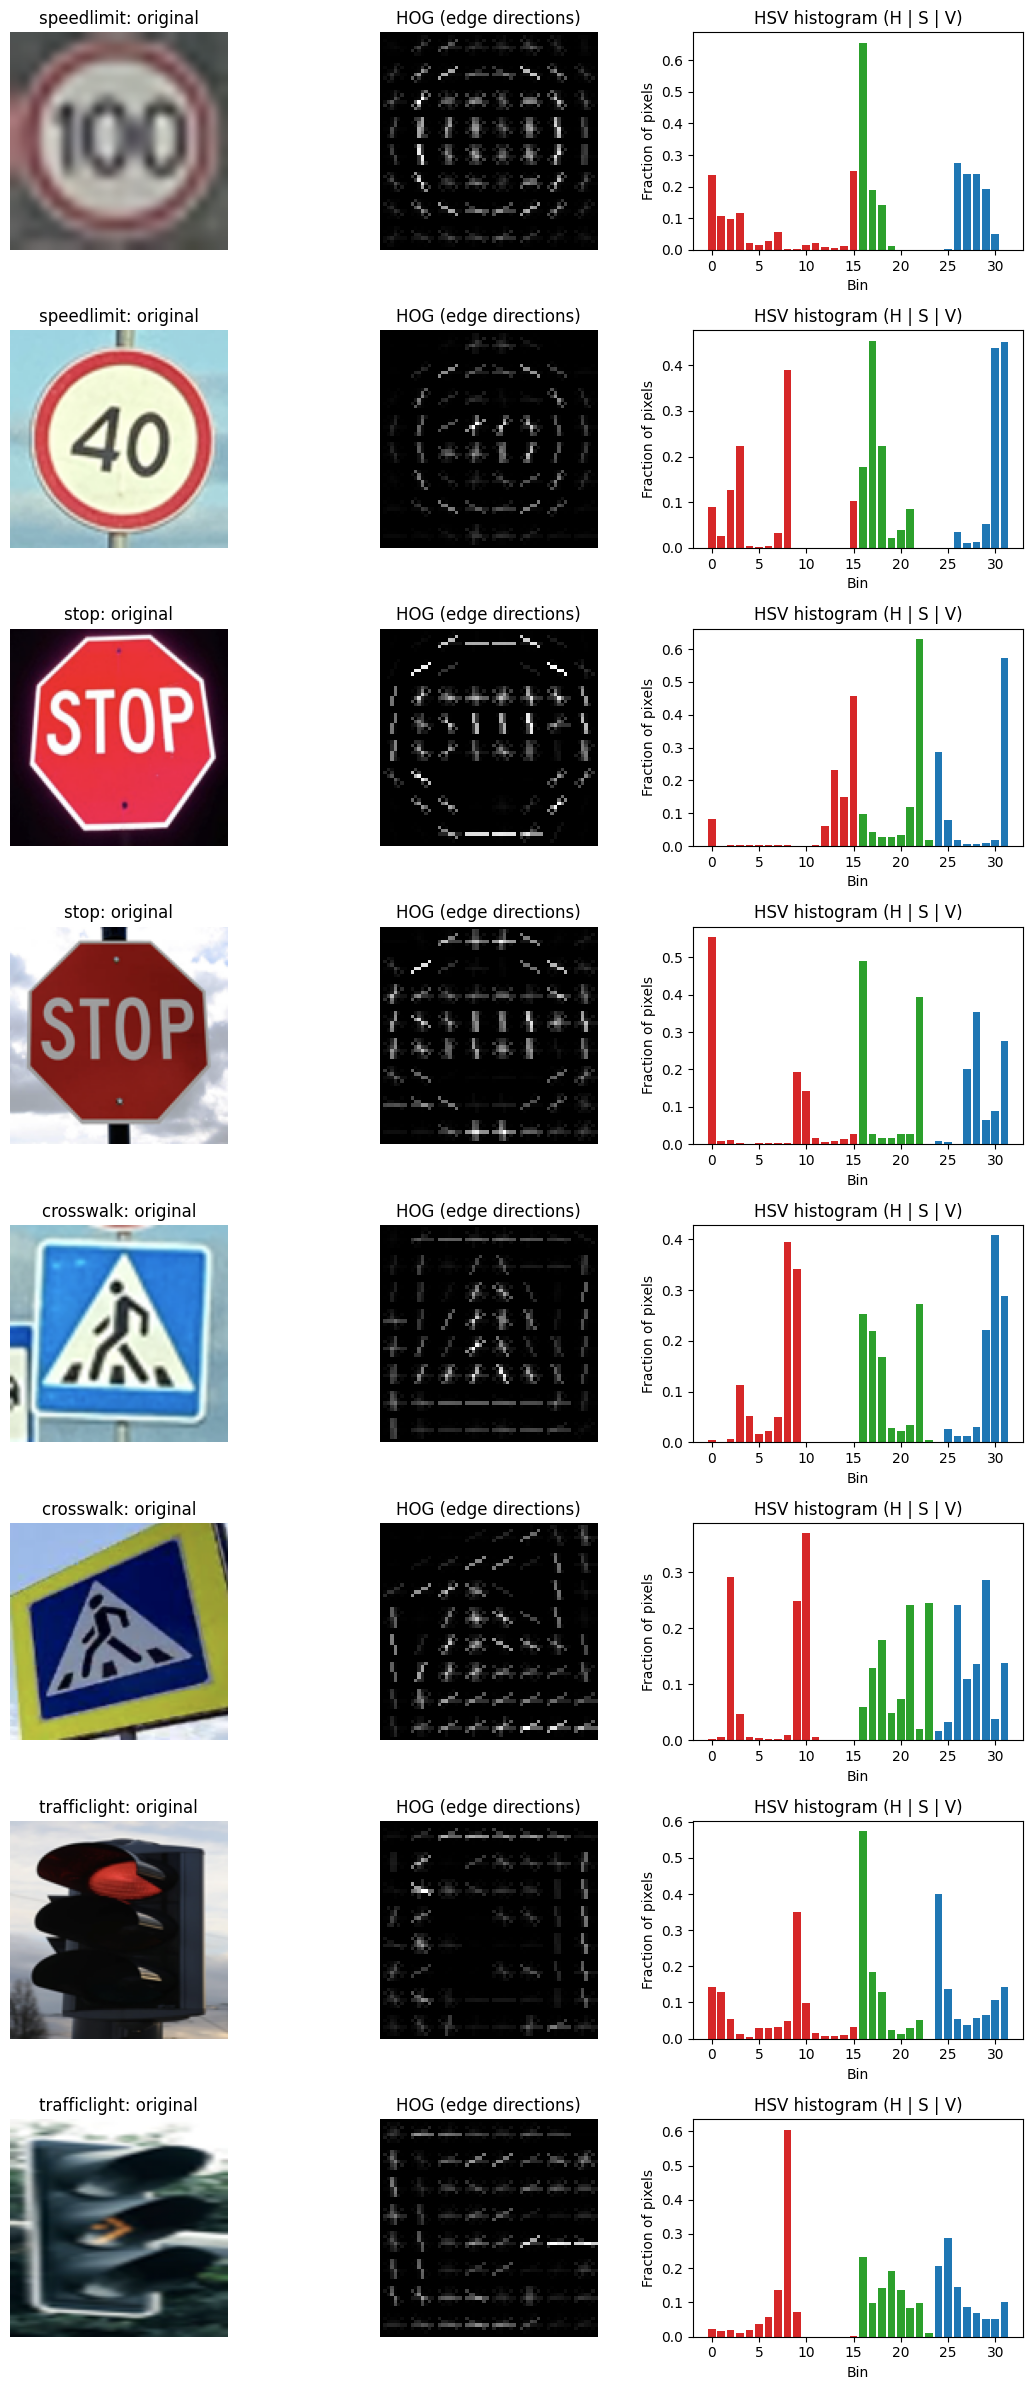

In [6]:
rng = np.random.default_rng(SEED)
n_per_class = 2
fig, axes = plt.subplots(len(CLASSES) * n_per_class, 3, figsize=(11, 3 * len(CLASSES) * n_per_class))
colors = ["tab:red"] * 16 + ["tab:green"] * 8 + ["tab:blue"] * 8

row = 0
for label in CLASSES:
    idx = rng.choice(np.where(y_train == label)[0], n_per_class, replace=False)
    for i in idx:
        img = X_train_img[i]
        gray = resize(rgb2gray(img), FEAT_SIZE, anti_aliasing=True)
        _, hog_img = hog(gray, visualize=True, **HOG_PARAMS)

        axes[row, 0].imshow(img); axes[row, 0].set_title(f"{label}: original")
        axes[row, 1].imshow(hog_img, cmap="gray"); axes[row, 1].set_title("HOG (edge directions)")
        for a in axes[row, :2]: a.axis("off")

        axes[row, 2].bar(range(32), extract_hsv_hist(img), color=colors)
        axes[row, 2].set(title="HSV histogram (H | S | V)", xlabel="Bin", ylabel="Fraction of pixels")
        row += 1

plt.tight_layout(); plt.show()

## 4. Extract and cache the features

Extraction time counts toward the cost in the efficiency comparison, so time it. Save with `save_features` so rows line up with the split CSVs.

In [7]:
FEATURE_NAME = "simple"

def extract_all(images, fn):
    return np.stack([fn(img) for img in images])

splits = {"train": X_train_img, "val": X_val_img, "test": X_test_img}
feature_time_s = 0.0
for split, imgs in splits.items():
    X, secs = timed(extract_all, imgs, extract_simple)
    save_features(X, FEATURE_NAME, split)
    feature_time_s += secs
    print(f"{split}: {X.shape}  {secs:.1f} s")

print(f"Total extraction time: {feature_time_s:.1f} s "
      f"({1000 * feature_time_s / sum(len(v) for v in splits.values()):.2f} ms per image)")

X_train, X_val, X_test = (load_features(FEATURE_NAME, s) for s in ["train", "val", "test"])
N_HOG = extract_hog(X_train_img[0]).shape[0]   # first N_HOG columns are HOG, the rest are HSV

train: (781, 1796)  8.1 s
val: (169, 1796)  1.5 s
test: (156, 1796)  2.0 s
Total extraction time: 11.6 s (10.49 ms per image)


## 5. PCA

The first two principal components already separate the classes well. PC 1 splits speed limits and stop signs (right) from crosswalks and traffic lights (left), and PC 2 separates crosswalks (top) from traffic lights (bottom). Stop signs form their own group but sit right next to the speed-limit cluster, which makes sense since both are red-bordered signs with dark symbols in the middle.

The cumulative variance curve rises slowly: the first component explains only about 16% of the variance, and we need 110 components for 80% and 288 for 95%. The information is spread across many HOG dimensions, so PCA is useful for visualization but would not shrink the feature much without losing detail.

80% of variance needs 110 components
90% of variance needs 200 components
95% of variance needs 288 components


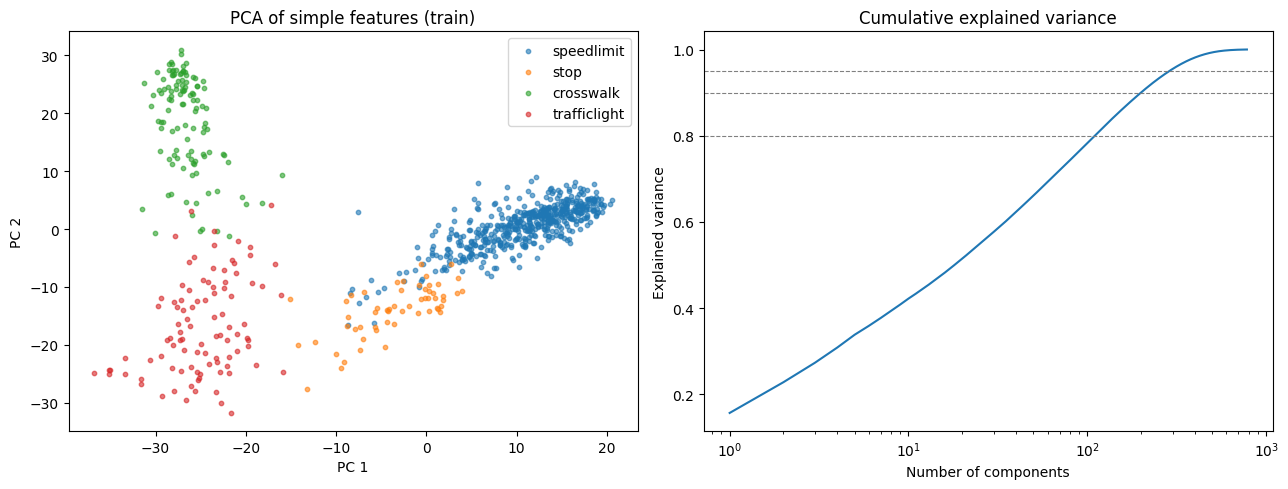

In [8]:
from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

scaler_vis = StandardScaler().fit(X_train)
Z_train = scaler_vis.transform(X_train)

pca = PCA(random_state=SEED).fit(Z_train)
Z2 = pca.transform(Z_train)[:, :2]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for label in CLASSES:
    m = y_train == label
    axes[0].scatter(Z2[m, 0], Z2[m, 1], s=10, alpha=0.6, label=label)
axes[0].set(title="PCA of simple features (train)", xlabel="PC 1", ylabel="PC 2")
axes[0].legend()

cum = np.cumsum(pca.explained_variance_ratio_)
axes[1].plot(np.arange(1, len(cum) + 1), cum)
for t in (0.8, 0.9, 0.95):
    k = np.searchsorted(cum, t) + 1
    axes[1].axhline(t, ls="--", c="gray", lw=0.8)
    print(f"{int(t*100)}% of variance needs {k} components")
axes[1].set(title="Cumulative explained variance", xlabel="Number of components",
            ylabel="Explained variance", xscale="log")
plt.tight_layout(); plt.show()

## 6. t-SNE

t-SNE shows four clearly separated groups at both perplexity values, confirming what PCA suggested: the simple features are enough to tell the classes apart. Stop signs, crosswalks and traffic lights each form one compact cluster. Speed limits split into several sub-clusters, most likely because different numbers (40, 60, 100, …) and backgrounds produce different HOG patterns. Perplexity 40 gives tighter, cleaner groups than 15.

A few points land in the wrong cluster: a handful of stop signs sit near speed limits and a few traffic lights sit near crosswalks. These are the same pairs the classifiers confuse in section 10.

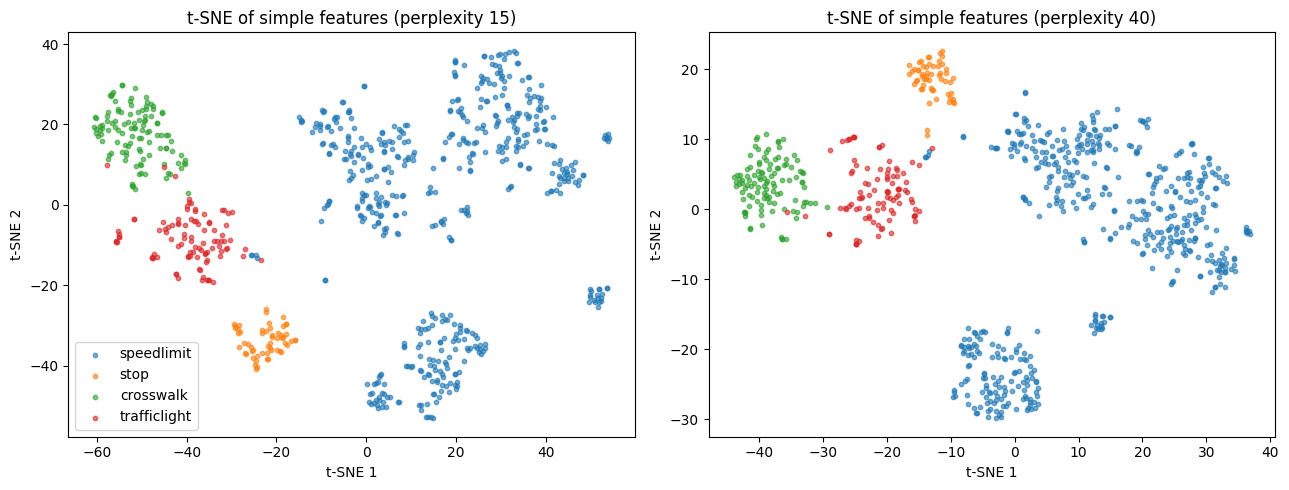

In [9]:
from sklearn.manifold import TSNE

Z50 = PCA(n_components=50, random_state=SEED).fit_transform(Z_train)  # PCA first speeds up t-SNE

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for ax, perp in zip(axes, [15, 40]):
    emb = TSNE(n_components=2, perplexity=perp, init="pca", random_state=SEED).fit_transform(Z50)
    for label in CLASSES:
        m = y_train == label
        ax.scatter(emb[m, 0], emb[m, 1], s=10, alpha=0.6, label=label)
    ax.set(title=f"t-SNE of simple features (perplexity {perp})", xlabel="t-SNE 1", ylabel="t-SNE 2")
axes[0].legend()
plt.tight_layout(); plt.show()

## 7. Why these features

Road signs are designed to be recognized from **shape and color**, so we use one feature for each.

**HOG** describes local edge directions. Our four classes have very different outlines and inner symbols: stop signs are octagons, speed limits are circles with digits, crosswalks are squares with a walking figure, and traffic lights are tall boxes with round lamps. HOG captures these, and its block normalization makes it fairly robust to lighting changes. Its weakness is blur: most of our crops are under 60 px, so fine edges are often lost. It also ignores color.

**HSV color histogram** describes which colors a sign contains, regardless of where they are. HSV separates hue from brightness, so a red stop sign still has red hue in shade or sun. It separates red stop signs from blue crosswalks well, but speed limits and traffic lights are both mostly neutral, and it throws away all shape information.

**Parameters**
- Both features use crops resized to **64×64**: large enough to keep the detail of small signs, small enough to keep the vector short.
- HOG: **9 orientations** (20° bins), **8×8 pixel cells** (about the scale of digits and symbols) and **2×2 cell blocks** with L2-Hys normalization for lighting robustness, giving 1,764 values.
- HSV: **16 hue bins** (hue carries most of the color information), **8 saturation** and **8 value** bins, each normalized to sum to 1, giving 32 values.
- The cached `simple` feature concatenates both (1,796 values).

**Each feature alone vs. combined** (logistic regression, validation set): HOG alone reached 0.988 accuracy (macro F1 0.983), the HSV histogram alone 0.817 (macro F1 0.753), and the combination 0.994 (macro F1 0.990). Shape does most of the work; color adds a small gain.

## 8. Classifier A: Logistic Regression

- Standardize features (`StandardScaler`, **fit on train only**).
- Use `class_weight="balanced"` because `stop` has far fewer examples than `speedlimit`.
- Search hyperparameters (for example `C`) by training on train and scoring on **validation**. Never use the test set here.

In [10]:
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, f1_score

scaler = StandardScaler().fit(X_train)          # fit on train only
Xtr, Xva, Xte = scaler.transform(X_train), scaler.transform(X_val), scaler.transform(X_test)

def val_scores(model):
    pred = model.predict(Xva)
    return accuracy_score(y_val, pred), f1_score(y_val, pred, average="macro")

lr_rows = []
for C in [0.0001, 0.001, 0.01, 0.1, 1, 10]:
    model = LogisticRegression(C=C, class_weight="balanced", max_iter=5000, random_state=SEED).fit(Xtr, y_train)
    acc, f1 = val_scores(model)
    lr_rows.append({"C": C, "val_acc": acc, "val_macro_f1": f1})

lr_grid = pd.DataFrame(lr_rows)
display(lr_grid)
best_lr = lr_grid.loc[lr_grid["val_macro_f1"].idxmax()]
lr_params = {"C": float(best_lr["C"])}
print("Best logistic regression:", lr_params, f"val acc {best_lr.val_acc:.3f}, macro F1 {best_lr.val_macro_f1:.3f}")

,C,val_acc,val_macro_f1
0,0.0001,0.994083,0.989533
1,0.0010,0.994083,0.989533
2,0.0100,0.994083,0.989533
3,0.1000,0.994083,0.989533
4,1.0000,0.988166,0.983412
5,10.0000,0.988166,0.983412


Best logistic regression: {'C': 0.0001} val acc 0.994, macro F1 0.990


In [11]:
def lr_val(cols):
    sc = StandardScaler().fit(X_train[:, cols])
    m = LogisticRegression(C=lr_params["C"], class_weight="balanced", max_iter=5000, random_state=SEED)
    m.fit(sc.transform(X_train[:, cols]), y_train)
    pred = m.predict(sc.transform(X_val[:, cols]))
    return accuracy_score(y_val, pred), f1_score(y_val, pred, average="macro")

all_cols = np.arange(X_train.shape[1])
ablation = pd.DataFrame(
    [("HOG only", *lr_val(all_cols[:N_HOG])),
     ("HSV histogram only", *lr_val(all_cols[N_HOG:])),
     ("HOG + HSV (simple)", *lr_val(all_cols))],
    columns=["features", "val_acc", "val_macro_f1"])
ablation

,features,val_acc,val_macro_f1
0,HOG only,0.988166,0.983412
1,HSV histogram only,0.816568,0.753345
2,HOG + HSV (simple),0.994083,0.989533


## 9. Classifier B: SVM

- Same scaling and class weighting as above.
- Search `C` and the kernel (linear vs. RBF, plus `gamma` for RBF) using validation only.
- Any two methods from class are fine (for example logistic regression, SVM, perceptron). Change these two if you prefer, but keep the **same two classifiers across notebooks 02-04** so the six combos are comparable.

In [12]:
from sklearn.svm import SVC

svm_rows = []
grid = [{"kernel": "linear", "C": C} for C in [0.001, 0.01, 0.1, 1]] + \
       [{"kernel": "rbf", "C": C, "gamma": g} for C in [1, 10, 100] for g in ["scale", 1e-4, 1e-3]]

for params in grid:
    model = SVC(class_weight="balanced", random_state=SEED, **params).fit(Xtr, y_train)
    acc, f1 = val_scores(model)
    svm_rows.append({**params, "val_acc": acc, "val_macro_f1": f1})

svm_grid = pd.DataFrame(svm_rows)
display(svm_grid.sort_values("val_macro_f1", ascending=False).head(8))
best_svm = svm_grid.loc[svm_grid["val_macro_f1"].idxmax()]
svm_params = {"kernel": best_svm["kernel"], "C": float(best_svm["C"])}
if best_svm["kernel"] == "rbf":
    svm_params["gamma"] = best_svm["gamma"] if isinstance(best_svm["gamma"], str) else float(best_svm["gamma"])
print("Best SVM:", svm_params, f"val acc {best_svm.val_acc:.3f}, macro F1 {best_svm.val_macro_f1:.3f}")

,kernel,C,val_acc,val_macro_f1,gamma
5,rbf,1.000,0.988166,0.979914,0.0001
1,linear,0.010,0.988166,0.978365,NaN
2,linear,0.100,0.988166,0.978365,NaN
3,linear,1.000,0.988166,0.978365,NaN
0,linear,0.001,0.988166,0.978365,NaN
11,rbf,100.000,0.988166,0.978365,0.0001
8,rbf,10.000,0.988166,0.978365,0.0001
10,rbf,100.000,0.976331,0.955795,scale


Best SVM: {'kernel': 'rbf', 'C': 1.0, 'gamma': 0.0001} val acc 0.988, macro F1 0.980


## 10. Final evaluation (run once)

With hyperparameters chosen, fit each classifier with its best settings and evaluate on the **test** set one time.

For each classifier:
- time training and time inference (use `timed`)
- compute accuracy and the per-class report with `evaluate(...)`
- plot the confusion matrix with `plot_confusion_matrix(...)`
- log it: `record_result(FEATURE_NAME, "<classifier>", val_acc, test_acc, train_time_s, infer_time_s, best_params, per_class_df, feature_time_s)`

In [13]:
def final_eval(name, model, params, best_row):
    _, train_time_s = timed(model.fit, Xtr, y_train)
    pred, infer_time_s = timed(model.predict, Xte)

    test_acc, per_class, cm = evaluate(y_test, pred)
    test_f1 = f1_score(y_test, pred, average="macro")
    print(f"{name}: val acc {best_row.val_acc:.3f} | test acc {test_acc:.3f} | test macro F1 {test_f1:.3f}")
    print(f"train {train_time_s:.2f} s | inference {1000 * infer_time_s / len(Xte):.3f} ms per image")
    display(per_class.round(3))
    plot_confusion_matrix(cm, title=f"{FEATURE_NAME} + {name} (test)")
    plt.show()

    record_result(FEATURE_NAME, name, best_row.val_acc, test_acc, train_time_s, infer_time_s,
                  best_params=params, per_class_df=per_class, feature_time_s=feature_time_s)

logreg: val acc 0.994 | test acc 0.987 | test macro F1 0.973
train 1.36 s | inference 0.039 ms per image


,precision,recall,f1-score,support
speedlimit,0.991,1.000,0.995,110.0
stop,1.000,0.929,0.963,14.0
crosswalk,1.000,0.950,0.974,20.0
trafficlight,0.923,1.000,0.960,12.0


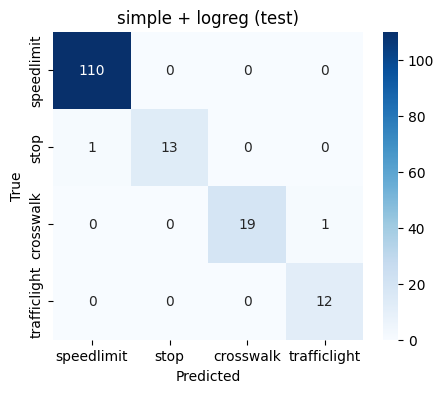

In [14]:
final_eval("logreg",
           LogisticRegression(**lr_params, class_weight="balanced", max_iter=5000, random_state=SEED),
           lr_params, best_lr)

svm: val acc 0.988 | test acc 0.981 | test macro F1 0.954
train 0.21 s | inference 0.499 ms per image


,precision,recall,f1-score,support
speedlimit,0.991,1.000,0.995,110.0
stop,1.000,0.857,0.923,14.0
crosswalk,1.000,0.950,0.974,20.0
trafficlight,0.857,1.000,0.923,12.0


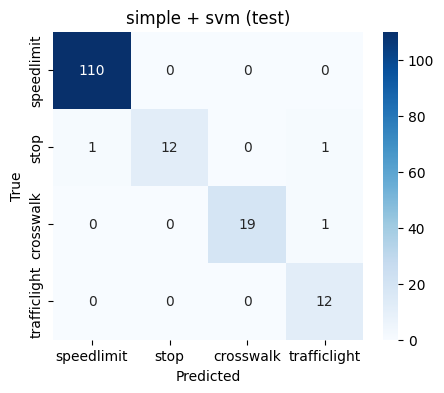

In [15]:
final_eval("svm",
           SVC(**svm_params, class_weight="balanced", random_state=SEED),
           svm_params, best_svm)

## 11. Per-class results and limitations

**What each classifier got right and wrong.** Logistic regression reached 0.987 test accuracy (macro F1 0.973) and the SVM 0.981 (macro F1 0.954). Both classified all 110 speed limits and all 12 traffic lights correctly. Logistic regression made only two mistakes: one stop sign predicted as a speed limit and one crosswalk predicted as a traffic light. The SVM made the same two mistakes plus one more stop sign predicted as a traffic light. The stop → speed limit confusion fits the PCA plot, where the two red-bordered classes sit next to each other. The other errors are likely blurry or oddly framed crops where HOG can't see a clear outline.

**Class imbalance.** Speed limit makes up about 66% of the data and is also the easiest class. With `class_weight="balanced"`, the models did not drift toward predicting speed limit, and recall on the small classes stayed high. However, the test set has only 12–20 examples of stop, crosswalk and traffic light, so one mistake moves a class's recall by 5–8 points (for example, stop recall drops from 0.93 to 0.86 for the SVM because of one extra error). That is why we report macro F1 alongside accuracy.

**Limits of this pairing.** HOG depends on clear edges, so small or blurred signs are the main source of error. The color histogram cannot separate neutral-colored classes and is affected by the background. Scores are already near the ceiling, so this dataset may be too easy to strongly separate the three feature types.

**Tuning and generalization.** Validation scores were nearly flat across `C` for logistic regression (0.988–0.994), so tuning mattered little; we kept the smallest `C` (strongest regularization) among the tied values. For the SVM, the RBF kernel with a small `gamma` and the linear kernel performed about the same. Test accuracy is about 0.7 points below validation for both models, a small gap that suggests both generalize well to unseen photos. Logistic regression is also faster at prediction (0.04 ms vs. 0.5 ms per image).